1. 실습코드00: ITK-SNAP으로 day15를 day0에 registration을 진행한 결과파일을 불러와서 같은 단면을 day0, day15에 대해 display하여 비교하기.

In [16]:
import numpy as np
import matplotlib.pyplot as plt

In [17]:
!pip install nibabel

In [18]:
import nibabel as nib

In [19]:
h = nib.load('volume-covid19-A-0700_day000.nii.gz')
print(h.shape)

(512, 512, 70)


In [20]:
ct_base = h.get_fdata()
print(ct_base.dtype, ct_base.shape)
print(np.min(ct_base),np.max(ct_base))

float64 (512, 512, 70)
-5363.0 30689.0


In [21]:
ct_FU = nib.load('volume-covid19-A-0700_day015.nii.gz').get_fdata()
ct_FU_reg = nib.load('volume-covid19-A-0700_day015-reg_to_day000.nii.gz').get_fdata()

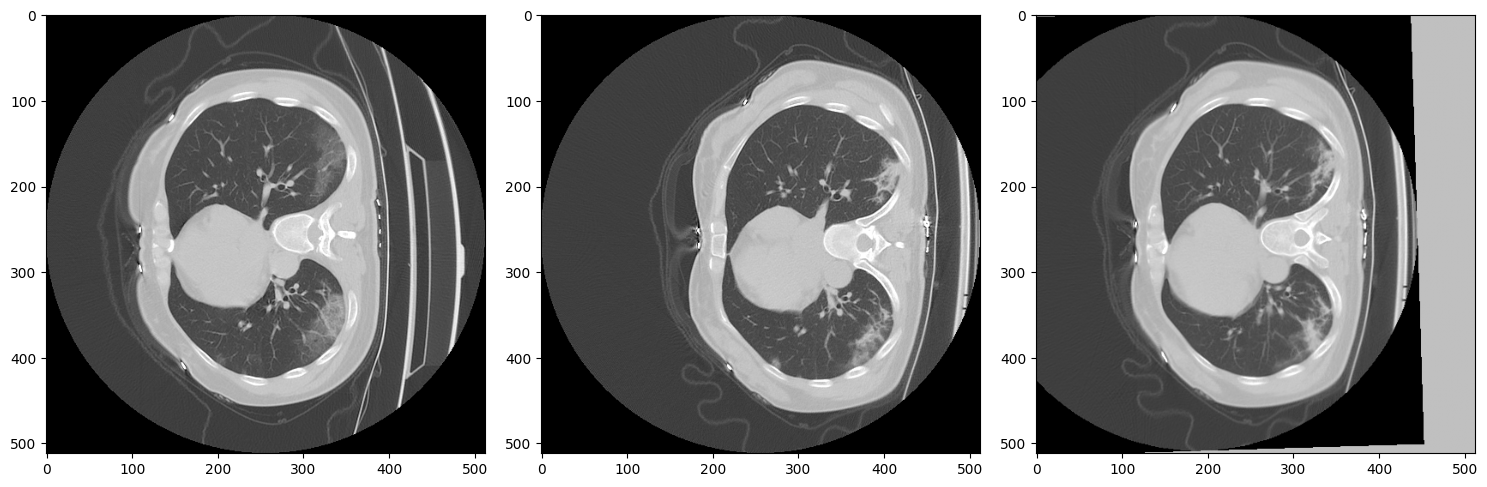

In [22]:
plt.figure(figsize=(15,5))
plt.subplot(131)
plt.imshow(ct_base[:,:,30],vmin=-1500,vmax=500,cmap='gray')
plt.subplot(132)
plt.imshow(ct_FU[:,:,30],vmin=-1500,vmax=500,cmap='gray')
plt.subplot(133)
plt.imshow(ct_FU_reg[:,:,30],vmin=-1500,vmax=500,cmap='gray')
plt.tight_layout()
plt.show()

2. 실습코드01: Exercise 1. local histogram equalization을 통해 숨겨진 패턴 확인하기

In [23]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [33]:
import os
imgpath = '/content/drive/MyDrive/DIP4E'

In [25]:
def histogram_equalization(image):
    histogram, bins = np.histogram(image.flatten(), bins=256, range=[0,256])
    cdf = histogram.cumsum()
    cdf_min = cdf.min()
    cdf_max = cdf.max()
    cdf_normalized = (cdf - cdf_min) * 255 / (cdf_max - cdf_min)
    cdf_normalized = cdf_normalized.astype(np.uint8)
    equalized_image = cdf_normalized[image]
    return equalized_os.listdir(imgpath)image

In [26]:
f = plt.imread(imgpath+'/hidden-symbols.tif')
print(f.shape,f.dtype)os.listdir(imgpath)

(256, 256) uint8


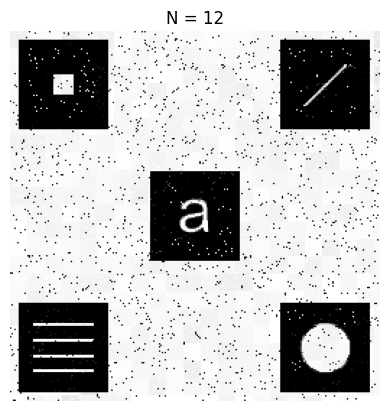

In [27]:
N = 12
f_eq_local = np.zeros_like(f)
for x in np.arange(0,256,N):
  for y in np.arange(0,256,N):
    f_eq_local[x:x+N,y:y+N] = histogram_equalization(f[x:x+N,y:y+N])

plt.imshow(f_eq_local,vmin=0,vmax=255,cmap='gray')
plt.axis('off')
plt.title(f'N = {N}')
plt.show()

3. 실습코드01: Exercise 2. 본인의 사진을 grayscale image로 불러온 후, 서로 다른 kernel size에 대한 LPF결과 비교

In [28]:
import scipy.signal as signal
from skimage import io

In [29]:
f = io.imread('mu.jpg',as_gray=True)
print(f.shape,f.dtype)

(4071, 3053) float64


In [30]:
import time

computation time =  1.1796693801879883  sec


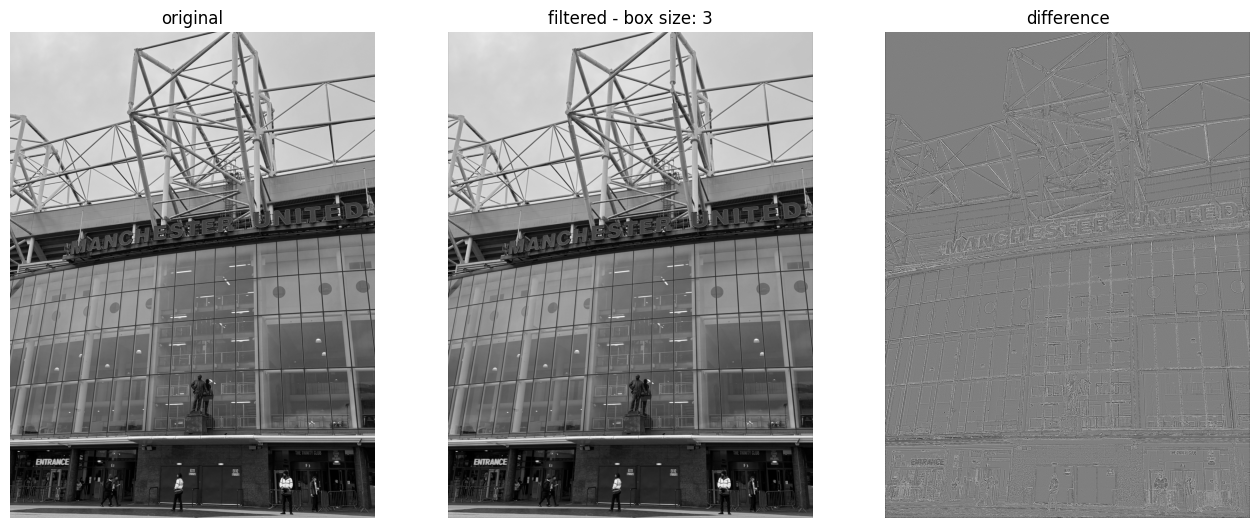

computation time =  1.1402888298034668  sec


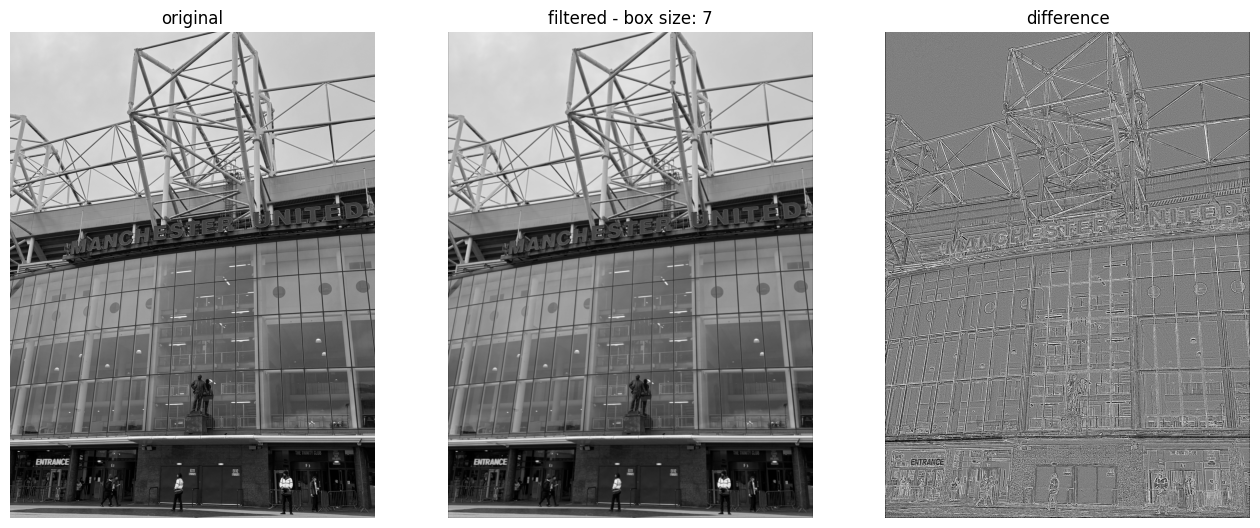

computation time =  5.489809513092041  sec


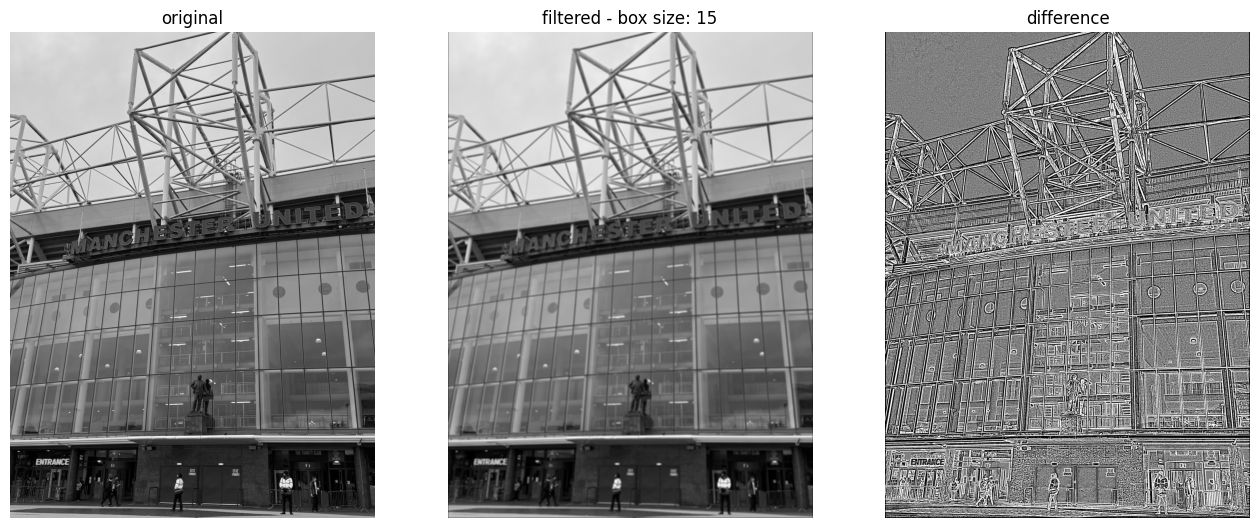

computation time =  15.960028409957886  sec


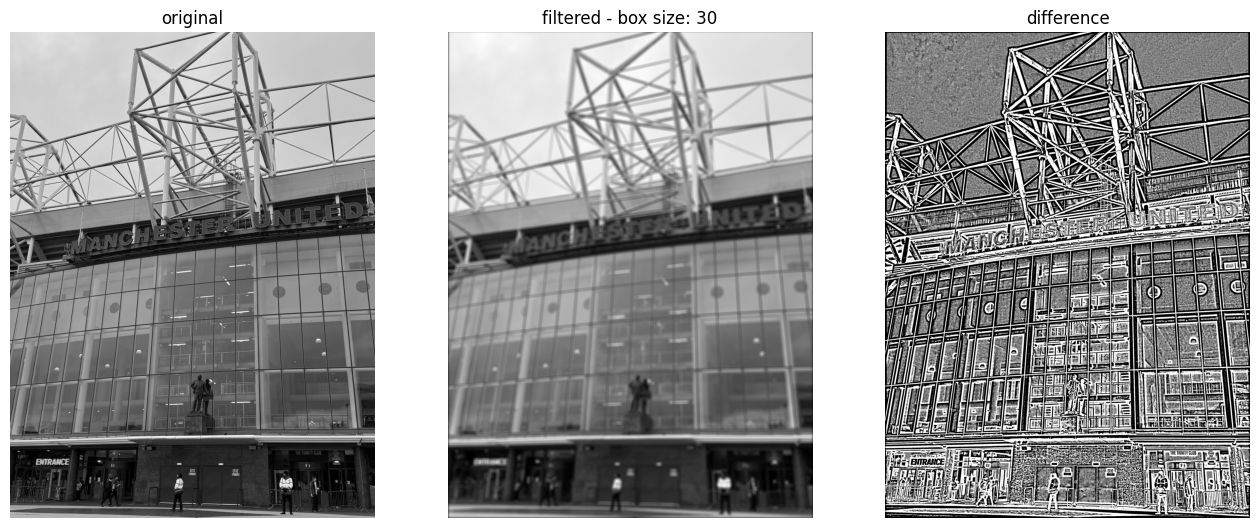

In [31]:
for N in np.array([3,7,15,30]):
  wb = np.ones((N,N))
  wb = wb/np.sum(wb)
  s0 = time.time()
  y_b = signal.convolve2d(f,wb,mode='same')
  compu_time=time.time() - s0
  print('computation time = ', compu_time,' sec')
  plt.figure(figsize=(16,9))
  plt.subplot(1,3,1)
  plt.imshow(f,cmap='gray')
  plt.axis('off')
  plt.title('original')
  plt.subplot(1,3,2)
  plt.imshow(y_b,cmap='gray')
  plt.axis('off')
  plt.title(f'filtered - box size: {N}')
  plt.subplot(1,3,3)
  plt.imshow(y_b-f,cmap='gray',vmin=-.01,vmax=.01)
  plt.axis('off')
  plt.title('difference')
  plt.show()

4. 실습코드01: Exercise 3. Blurring이 발생한 사진을 가져와서 적당한 HPF결과를 활용하여 sharpening을 진행하기

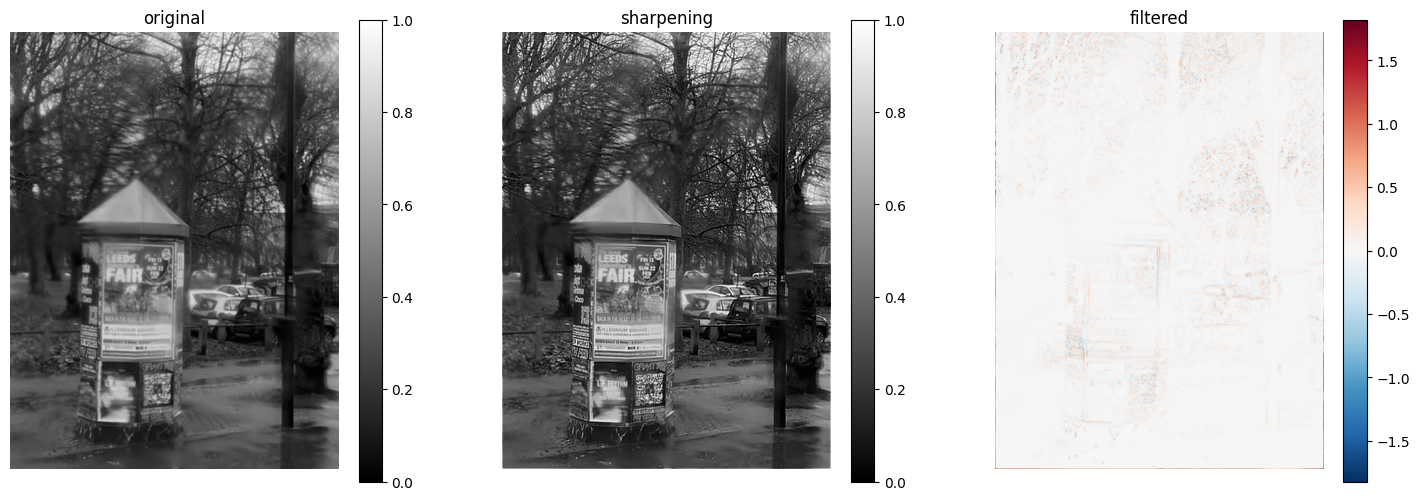

In [32]:
f = io.imread('blurred.jpg', as_gray=True)
#f = io.imread('https://superresolution.co/wp-content/uploads/2024/08/superresolution-types-of-blurred-images-num5.webp',as_gray=True)[::2,::2]

w = ([[-1,-1,-1],[-1,8,-1],[-1,-1,-1]])
y = signal.convolve2d(f,w,mode='same')
c = 0.5
g = f + c*(y)
plt.figure(figsize=(18,6))
plt.subplot(131)
plt.imshow(f,cmap='gray', vmin=0, vmax=1)
plt.colorbar()
plt.axis('off')
plt.title('original')
plt.subplot(132)
plt.imshow(g,cmap='gray', vmin=0, vmax=1)
plt.colorbar()
plt.axis('off')
plt.title('sharpening')
plt.subplot(133)
plt.imshow(y,cmap='RdBu_r',vmin=-0.5*np.max(np.abs(y)),vmax=0.5*np.max(np.abs(y)))
plt.colorbar()
plt.axis('off')
plt.title('filtered')
plt.show()